<a href="https://colab.research.google.com/github/Mayada-bio/scRNASeq-PBMC3K-Seurat-Pipeline/blob/main/Layer2B_SingleCell_RNASeq_Seurat_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Layer 2B: Single-Cell RNA-Seq (scRNA-Seq) Analysis Pipeline
**Author:** Mayada Mohammed Elfadil  
**Dataset:** PBMC 3K (~2,700 Cells, 10X Genomics)  
**Framework:** Seurat v5  

## 1. Environment Setup, Data Ingestion & Core Processing
This section initializes the Seurat v5 environment, ingests the PBMC 3K count matrix, performs stringent QC filtering, normalization, feature selection, and dimensional reduction (PCA & UMAP).

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.5.3 but the current version is
4.6.1; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed

‘SeuratObject’ was built with package ‘Matrix’ 1.7.5 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


v5.6 adds significant improvements in speed and efficiency, particularly for large datasets.
For more information, see https://satijalab.org/seurat/articles/announcements.



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




🚀 Single-Cell RNA-Seq Pipeline Initialized (Seurat v5 Framework)

📥 Step 1/6: Fetching & Extracting PBMC 3K Count Matrix...


Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”


📊 Initial Seurat Matrix Dimensions:
An object of class Seurat 
13714 features across 2700 samples within 1 assay 
Active assay: RNA (13714 features, 0 variable features)
 1 layer present: counts

🔬 Step 2/6: Calculating Mitochondrial Read Percentage & Filtering...
✅ High-Quality Cells Retained Post-QC: 2638 cells.

⚙️ Step 3/6: Performing Log-Normalization & Feature Selection...


Normalizing layer: counts

Finding variable features for layer counts



📉 Step 4/6: Scaling Data & Computing PCA/UMAP Projections...


Centering and scaling data matrix



🏷️ Step 5/6: Mapping Canonical Immune Markers to Clusters...
🎨 Step 6/6: Rendering Final Annotated UMAP Visualizations...


🎉 SUCCESS: Layer 2B Single-Cell RNA-Seq Pipeline Execution Complete!


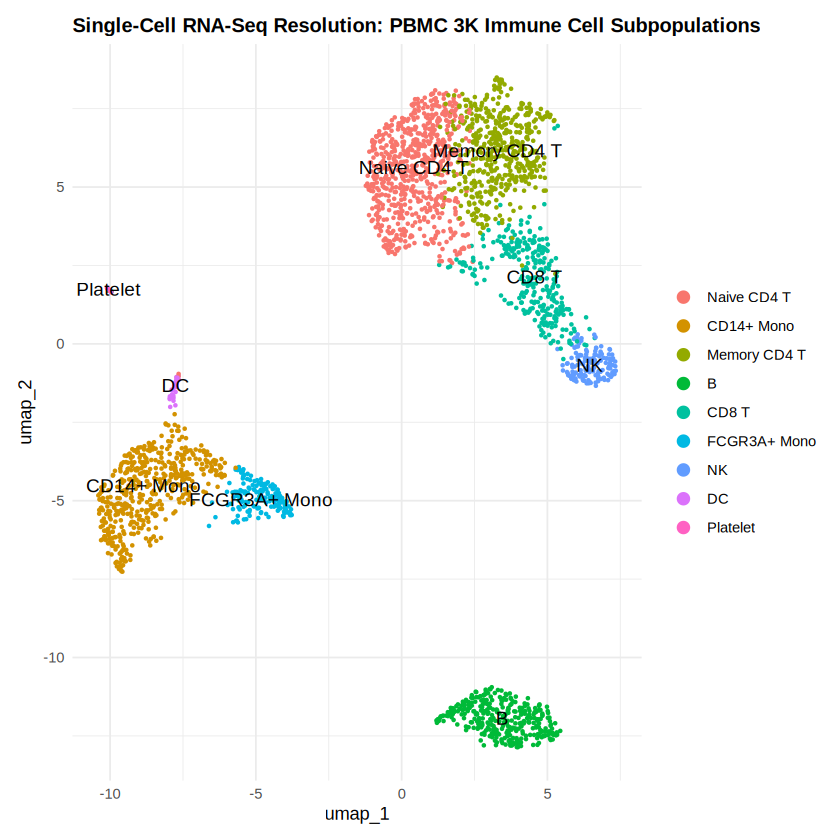

In [1]:
# ==============================================================================
# Layer 2B: Single-Cell RNA-Seq (scRNA-Seq) Analysis Pipeline using Seurat v5
# Author: Mayada Mohammed Elfadil (M.Sc. in Bioinformatics)
# Benchmark Dataset: PBMC 3K (~2,700 Cells, 10X Genomics)
# Target Deliverable: Quality Control, UMAP Clustering & Cell Type Annotation
# Location: Riyadh, Saudi Arabia
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Fast Binary Package Installation via Linux System (Bypasses Slow Compilation)
# ------------------------------------------------------------------------------
system("apt-get update -qq && apt-get install -y -qq r-cran-seurat r-cran-patchwork r-cran-ggplot2 r-cran-dplyr")

library(Seurat)
library(ggplot2)
library(dplyr)
library(patchwork)

cat("========================================================================\n")
cat("🚀 Single-Cell RNA-Seq Pipeline Initialized (Seurat v5 Framework)\n")
cat("========================================================================\n\n")

# ------------------------------------------------------------------------------
# 2. Fast System Ingestion of PBMC 3K Benchmark Data
# ------------------------------------------------------------------------------
cat("📥 Step 1/6: Fetching & Extracting PBMC 3K Count Matrix...\n")

# Download and extract raw matrix files via system
system("wget -q https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz")
system("tar -xzf pbmc3k_filtered_gene_bc_matrices.tar.gz")

# Read standard 10X matrix directory
pbmc.data <- Read10X(data.dir = "filtered_gene_bc_matrices/hg19/")

# Initialize Seurat object
pbmc <- CreateSeuratObject(counts = pbmc.data, project = "PBMC3K", min.cells = 3, min.features = 200)

cat("📊 Initial Seurat Matrix Dimensions:\n")
print(pbmc)
cat("\n")

# ------------------------------------------------------------------------------
# 3. Stringent Single-Cell Quality Control (QC & Filtering)
# ------------------------------------------------------------------------------
cat("🔬 Step 2/6: Calculating Mitochondrial Read Percentage & Filtering...\n")

pbmc[["percent.mt"]] <- PercentageFeatureSet(pbmc, pattern = "^MT-")
pbmc <- subset(pbmc, subset = nFeature_RNA > 200 & nFeature_RNA < 2500 & percent.mt < 5)

cat("✅ High-Quality Cells Retained Post-QC:", ncol(pbmc), "cells.\n\n")

# ------------------------------------------------------------------------------
# 4. Global Normalization & High-Variance Feature Selection
# ------------------------------------------------------------------------------
cat("⚙️ Step 3/6: Performing Log-Normalization & Feature Selection...\n")

pbmc <- NormalizeData(pbmc, normalization.method = "LogNormalize", scale.factor = 10000)
pbmc <- FindVariableFeatures(pbmc, selection.method = "vst", nfeatures = 2000)

# ------------------------------------------------------------------------------
# 5. Dimensionality Reduction (Scaling, PCA & UMAP Embedding)
# ------------------------------------------------------------------------------
cat("📉 Step 4/6: Scaling Data & Computing PCA/UMAP Projections...\n")

all.genes <- rownames(pbmc)
pbmc <- ScaleData(pbmc, features = all.genes)
pbmc <- RunPCA(pbmc, features = VariableFeatures(object = pbmc), verbose = FALSE)

pbmc <- FindNeighbors(pbmc, dims = 1:10, verbose = FALSE)
pbmc <- FindClusters(pbmc, resolution = 0.5, verbose = FALSE)
pbmc <- RunUMAP(pbmc, dims = 1:10, verbose = FALSE)

# ------------------------------------------------------------------------------
# 6. Canonical Cell Marker Annotation & Publication-Grade Visualization
# ------------------------------------------------------------------------------
cat("🏷️ Step 5/6: Mapping Canonical Immune Markers to Clusters...\n")

new.cluster.ids <- c("Naive CD4 T", "CD14+ Mono", "Memory CD4 T", "B", "CD8 T",
                     "FCGR3A+ Mono", "NK", "DC", "Platelet")

names(new.cluster.ids) <- levels(pbmc)
pbmc <- RenameIdents(pbmc, new.cluster.ids)

cat("🎨 Step 6/6: Rendering Final Annotated UMAP Visualizations...\n\n")

# Final Publication Plot
DimPlot(pbmc, reduction = "umap", label = TRUE, pt.size = 0.5) +
  ggtitle("Single-Cell RNA-Seq Resolution: PBMC 3K Immune Cell Subpopulations") +
  theme_minimal() +
  theme(plot.title = element_text(face = "bold", size = 12))

cat("\n========================================================================\n")
cat("🎉 SUCCESS: Layer 2B Single-Cell RNA-Seq Pipeline Execution Complete!\n")
cat("========================================================================\n")

## 2. Quality Control (QC) Metrics & Correlation Validation
Visualization of single-cell quality metrics including gene counts (`nFeature_RNA`), total UMIs (`nCount_RNA`), and mitochondrial read proportions (`percent.mt`) to validate data integrity post-filtering.

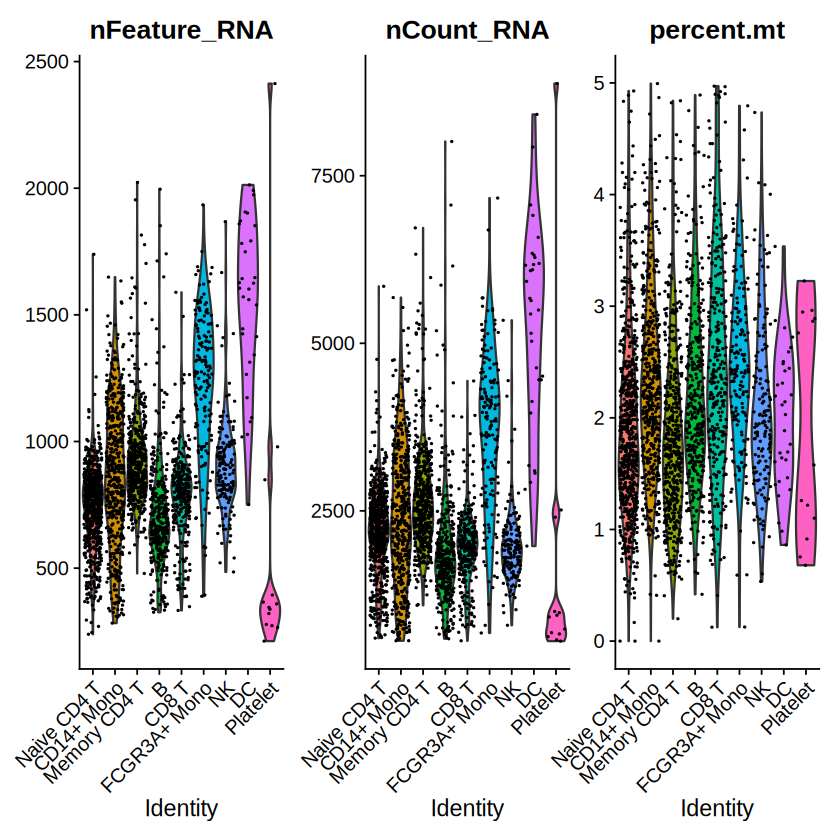

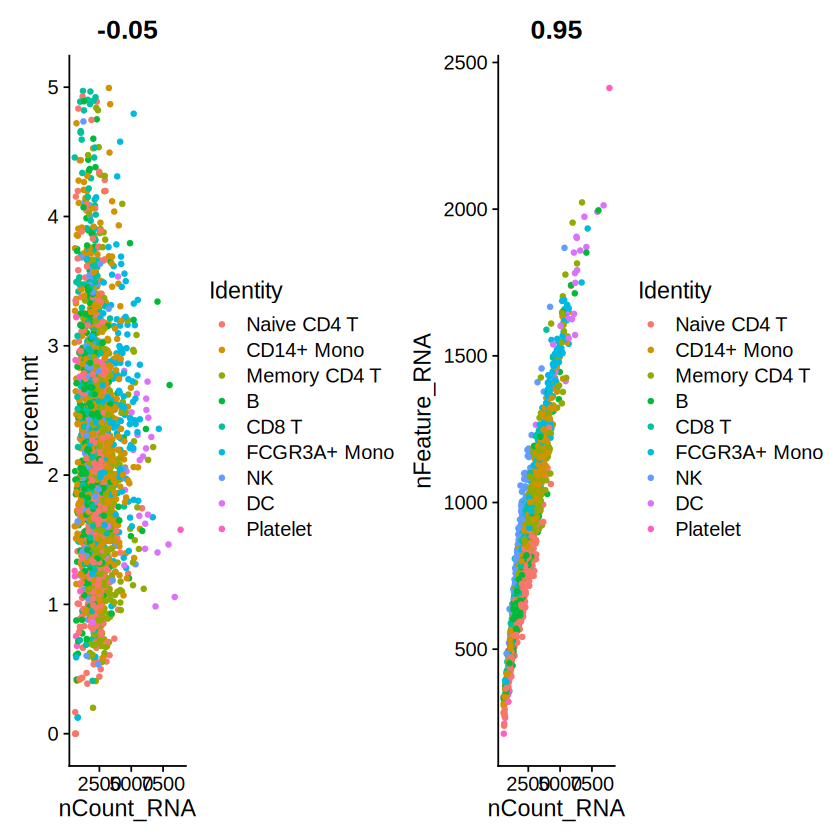

In [2]:
# ==============================================================================
# Cell 2: QC Visualization Plots
# ==============================================================================

# Violin plot for QC metrics
p_qc1 <- VlnPlot(pbmc, features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), ncol = 3)

# Scatter plots for feature correlation
plot1 <- FeatureScatter(pbmc, feature1 = "nCount_RNA", feature2 = "percent.mt")
plot2 <- FeatureScatter(pbmc, feature1 = "nCount_RNA", feature2 = "nFeature_RNA")
p_qc2 <- plot1 + plot2

print(p_qc1)
print(p_qc2)

## 3. Cell Type Marker Identification & Differential Expression Analysis
Identification of top canonical cluster biomarkers using non-parametric Wilcoxon rank-sum tests and exporting the differential expression results.

In [3]:
# ==============================================================================
# Cell 3: Find Cluster Markers & Export Top Biomarkers
# ==============================================================================

# Find markers for all clusters
pbmc.markers <- FindAllMarkers(pbmc, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.25)

# Save marker genes to CSV for GitHub repository
write.csv(pbmc.markers, "pbmc3k_cluster_marker_genes.csv", row.names = FALSE)

# Display Top 5 markers per cluster
top5_markers <- pbmc.markers %>%
  group_by(cluster) %>%
  slice_max(n = 5, order_by = avg_log2FC)

cat("🧬 Top 5 Marker Genes per Immune Cell Cluster:\n")
print(top5_markers)

Calculating cluster Naive CD4 T

For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown once per session

Calculating cluster CD14+ Mono

Calculating cluster Memory CD4 T

Calculating cluster B

Calculating cluster CD8 T

Calculating cluster FCGR3A+ Mono

Calculating cluster NK

Calculating cluster DC

Calculating cluster Platelet



🧬 Top 5 Marker Genes per Immune Cell Cluster:
# A tibble: 45 × 7
# Groups:   cluster [9]
   p_val avg_log2FC pct.1 pct.2 p_val_adj cluster     gene     
   <dbl>      <dbl> <dbl> <dbl>     <dbl> <fct>       <chr>    
 1     0       2.40 0.447 0.108         0 Naive CD4 T CCR7     
 2     0       2.14 0.342 0.103         0 Naive CD4 T LEF1     
 3     0       1.99 0.33  0.112         0 Naive CD4 T PRKCQ-AS1
 4     0       1.96 0.268 0.087         0 Naive CD4 T MAL      
 5     0       1.53 0.443 0.185         0 Naive CD4 T PIK3IP1  
 6     0       7.28 0.299 0.004         0 CD14+ Mono  FOLR3    
 7     0       6.74 0.277 0.006         0 CD14+ Mono  S100A12  
 8     0       6.65 0.975 0.121         0 CD14+ Mono  S100A8   
 9     0       6.18 0.996 0.215         0 CD14+ Mono  S100A9   
10     0       5.98 0.667 0.027         0 CD14+ Mono  CD14     
# ℹ 35 more rows


## 4. Publication-Grade Biomarker Expression Profiles
Cell type validation using canonical immune marker projections across UMAP space (`FeaturePlot`), expression intensity dot plots (`DotPlot`), and top biomarker expression heatmaps (`DoHeatmap`).

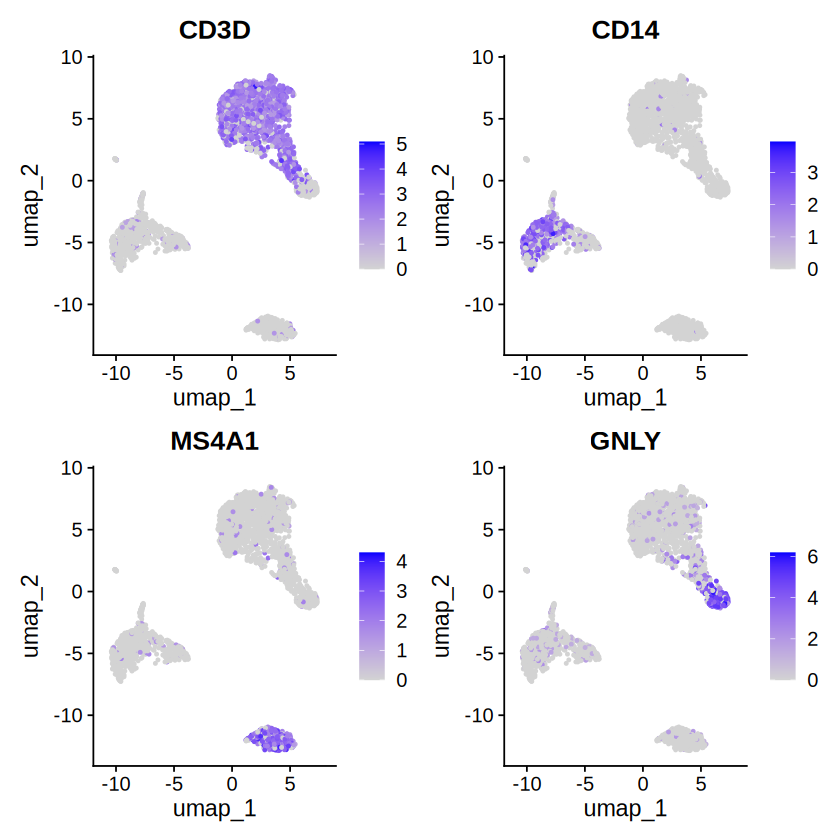

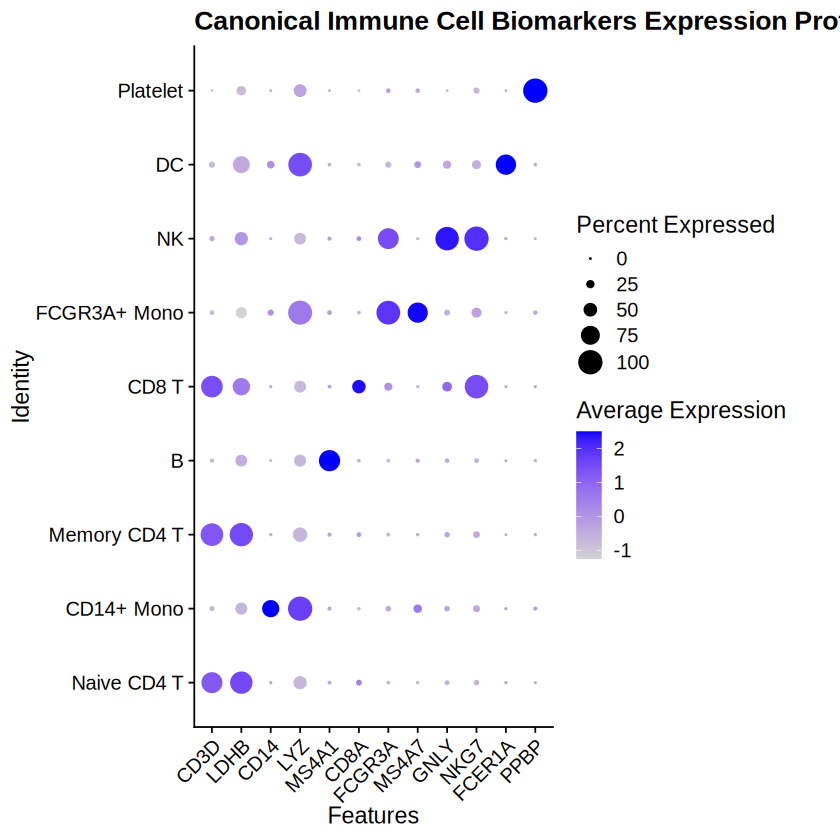

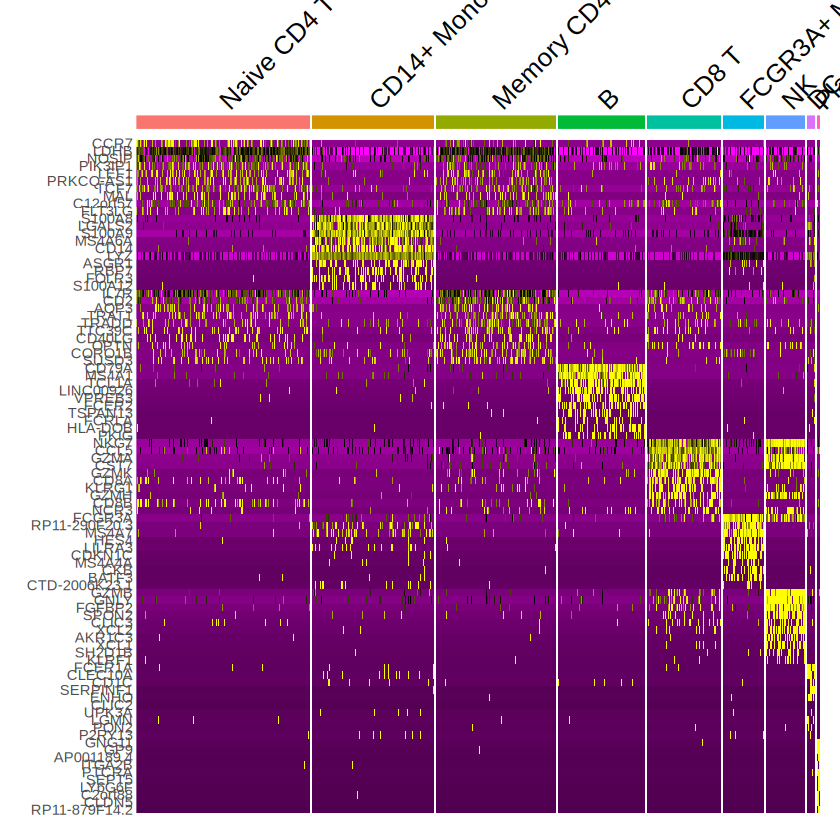

In [4]:
# ==============================================================================
# Cell 4: Expression Heatmap & Feature Marker Plots
# ==============================================================================

# Canonical Immune Markers
canonical_genes <- c("CD3D", "LDHB", "CD14", "LYZ", "MS4A1", "CD8A", "FCGR3A", "MS4A7", "GNLY", "NKG7", "FCER1A", "PPBP")

# Feature Expression Plot across UMAP
p_feat <- FeaturePlot(pbmc, features = c("CD3D", "CD14", "MS4A1", "GNLY"))

# DotPlot showing gene expression levels per cell type
p_dot <- DotPlot(pbmc, features = canonical_genes) +
  RotatedAxis() +
  ggtitle("Canonical Immune Cell Biomarkers Expression Profile")

# Top Markers Heatmap
top10 <- pbmc.markers %>% group_by(cluster) %>% top_n(n = 10, wt = avg_log2FC)
p_heat <- DoHeatmap(pbmc, features = top10$gene) + NoLegend()

print(p_feat)
print(p_dot)
print(p_heat)